# Object and Named Entity Recognition


[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/SvenjaGuhr/SoSe2027_Computational_Methods_for_Digital_Humanities/blob/main/notebooks/ner_object_detection.ipynb)

Two tasks:

1. **Images → object detection.**
2. **Text → named entity recognition.** Look for persons (**PER**) and organizations (**ORG**) uploaded wikipedia article.

*How to run:* click a cell and press **Shift+Enter**, from top to bottom.


## Step 0 — Setup
This installs spaCy's medium English model en_core_web_md.  On Google Colab, `torch` and `torchvision` are already available. This takes a minute or two.

In [39]:
# Install the libraries we need
!python -m spacy download en_core_web_md -q
print("Setup done. Please continue with the next cell.")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 33.5/33.5 MB 24.5 MB/s eta 0:00:00
✔ Download and installation successful
You can now load the package via spacy.load('en_core_web_md')
⚠ Restart to reload dependencies
If you are in a Jupyter or Colab notebook, you may need to restart Python in
order to load all the package's dependencies. You can do this by selecting the
'Restart kernel' or 'Restart runtime' option.
Setup done. Please continue with the next cell.


# Part A — Objects in images

Let us begin somewhere unexpected for a text-focused field: a photograph. The question is the same one we will later ask of text. What are the "things" here, and how does a model find them?

We use a detector trained on **COCO**, a dataset with 80 everyday object classes. The detector draws a **bounding box** around each object it recognizes and labels it.

First, give the notebook an image. Run the cell and upload a photo from the article, for example a team photo or a match photo.

*Rights reminder:* the article text is CC BY-SA, but each image carries its own license. Photos on Wikimedia Commons are often freely licensed, while the club crest is usually a non-free logo. For class display this is fine; for anything you publish, check each image's license.

In [40]:
import requests

# Use the file name from Wikimedia Commons (the part after "File:")
FILE_NAME = "SK_Sturm_Graz_20260805_(21).JPG"
IMAGE_URL = f"https://commons.wikimedia.org/wiki/Special:FilePath/{FILE_NAME}?width=1200"

#Since we are scraping open data, it is common practice to indicate your identity and purpose.
headers = {"User-Agent": "teaching-notebook/1.0 (https://github.com/SvenjaGuhr/SoSe2027_Introduction_to_Computational_Methods_for_Digital_Humanists)"}

#
image_path = "image.jpg"
r = requests.get(IMAGE_URL, headers=headers, timeout=30)
r.raise_for_status()
with open(image_path, "wb") as f:
    f.write(r.content)

print("Using image:", image_path)

Using image: image.jpg


Now run the detector. The first run downloads the model weights (about 160 MB), which takes a moment.

Detections (score >= 0.6):
   person         1.00
   person         1.00
   person         1.00
   person         1.00
   person         1.00
   person         1.00
   person         1.00
   person         0.99
   sports ball    0.89
   person         0.78


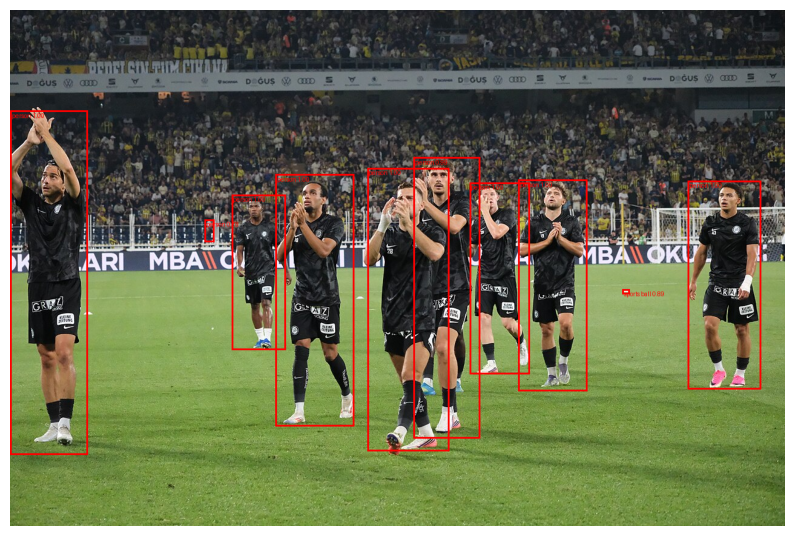

In [7]:
import torch
from torchvision.models.detection import (
    fasterrcnn_resnet50_fpn, FasterRCNN_ResNet50_FPN_Weights,
)
from PIL import Image, ImageDraw, ImageFont
import matplotlib.pyplot as plt

COCO_CATEGORIES = [
    "__background__","person","bicycle","car","motorcycle","airplane","bus","train",
    "truck","boat","traffic light","fire hydrant","stop sign","parking meter",
    "bench","bird","cat","dog","horse","sheep","cow","elephant","bear","zebra",
    "giraffe","N/A","backpack","umbrella","handbag","tie","suitcase",
    "frisbee","skis","snowboard","sports ball","kite","baseball bat","baseball glove",
    "skateboard","surfboard","tennis racket","bottle","wine glass","cup","fork",
    "knife","spoon","bowl","banana","apple","sandwich","orange","broccoli","carrot",
    "hot dog","pizza","donut","cake","chair","couch","potted plant","bed",
    "dining table","toilet","tv","laptop","mouse","remote","keyboard",
    "cell phone","microwave","oven","toaster","sink","refrigerator","book","clock",
    "vase","scissors","teddy bear","hair drier","toothbrush",
]

THRESHOLD = 0.6   # only show detections the model is at least 60% sure about

weights = FasterRCNN_ResNet50_FPN_Weights.DEFAULT
model = fasterrcnn_resnet50_fpn(weights=weights)
model.eval()

image = Image.open(image_path).convert("RGB")
tensor = weights.transforms()(image)
with torch.no_grad():
    prediction = model([tensor])[0]

draw = ImageDraw.Draw(image)
try:
    font = ImageFont.truetype("DejaVuSans.ttf", 18)
except OSError:
    font = ImageFont.load_default()

print(f"Detections (score >= {THRESHOLD}):")
found = 0
for box, label_id, score in zip(prediction["boxes"], prediction["labels"], prediction["scores"]):
    if score < THRESHOLD:
        continue
    found += 1
    label = COCO_CATEGORIES[label_id]
    x0, y0, x1, y1 = [float(v) for v in box]
    print(f"   {label:<14} {score:.2f}")
    draw.rectangle([x0, y0, x1, y1], outline="red", width=3)
    draw.text((x0 + 2, y0 + 2), f"{label} {score:.2f}", fill="red", font=font)
if found == 0:
    print("   (nothing above the threshold - try lowering THRESHOLD)")

plt.figure(figsize=(10, 8))
plt.imshow(image)
plt.axis("off")
plt.show()

### What the detector can and cannot see

Every label above comes from the 80-class COCO scheme. On a football photo you will typically see `person` and `sports ball`, and little else. There is **no class for a club crest, a jersey, or a goal**, so the model cannot find them, even though they are the most football-specific things in the picture.

That gap is the whole point: the model sees only the categories its scheme defines. Keep this in mind as we turn to text, where the same thing happens with persons and organizations.

**To take further:** lower `THRESHOLD` to 0.3 and re-run. More boxes appear, but more of them are wrong. That trade-off between finding more (recall) and being right (precision) is exactly what we measure next.

# Part B — Named entities in text

A **named entity** is a span of text that names a thing of a certain type. We care about two:
- **PER** — a person (a coach or a player)
- **ORG** — an organization (a football club or a league)

We start with the trained model `en_core_web_sm`. Note that spaCy calls the person type `PERSON`; we treat that as `PER`.

In [43]:
import requests
import spacy
from spacy import displacy


nlp = spacy.load("en_core_web_md")

# Lead section ("first section") of the English Wikipedia article as plain text
URL = "https://en.wikipedia.org/w/api.php"
params = {
    "action": "query",
    "prop": "extracts",
    "exintro": 1,        # only the lead section, before the first heading
    "explaintext": 1,    # plain text, no HTML
    "titles": "SK Sturm Graz",
    "format": "json",
    "formatversion": 2,
}
headers = {"User-Agent": "teaching-notebook/1.0 (https://github.com/SvenjaGuhr/SoSe2027_Introduction_to_Computational_Methods_for_Digital_Humanists)"}

try:
    r = requests.get(URL, params=params, headers=headers, timeout=30)
    r.raise_for_status()
    passage = r.json()["query"]["pages"][0]["extract"]
    print("Source: English Wikipedia, 'SK Sturm Graz' (lead section, CC BY-SA 4.0)\n")
except Exception as e:
    print("Could not load Wikipedia, using the fallback passage:", e)
    passage = (
        "SK Sturm Graz is an Austrian association football club based in Graz. "
        "Sturm's main rival is Grazer AK, and meetings between the two are called the Graz derby. "
        "Among its best-known coaches are Ivica Osim and Franco Foda."
    )

doc = nlp(passage)

# Interactive, color-coded view of every entity the model found:
displacy.render(doc, style="ent", jupyter=True)

# Or filtered for entities of interest:
#displacy.render(doc, style="ent", jupyter=True, options={"ents": ["PERSON", "ORG"]})


Source: English Wikipedia, 'SK Sturm Graz' (lead section, CC BY-SA 4.0)



### What did the model find?
The table lists every entity, its label, and what the label means. Look closely at how the football clubs are labeled.

In [44]:
import pandas as pd

'''
KEEP = ["PERSON", "ORG"]

rows = [(ent.text, ent.label_, spacy.explain(ent.label_))
        for ent in doc.ents if ent.label_ in KEEP]
pd.DataFrame(rows, columns=["text", "spaCy label", "meaning"])
'''

rows = [(ent.text, ent.label_, spacy.explain(ent.label_)) for ent in doc.ents]
pd.DataFrame(rows, columns=["text", "spaCy label", "meaning"])

,text,spaCy label,meaning
0,Sportklub Sturm Graz,PERSON,"People, including fictional"
1,Graz Storm',ORG,"Companies, agencies, institutions, etc."
2,Austrian,NORP,Nationalities or religious or political groups
3,Graz,GPE,"Countries, cities, states"
4,Austrian,NORP,Nationalities or religious or political groups
5,1909,DATE,Absolute or relative dates or periods
6,Sturm Graz,PERSON,"People, including fictional"
7,Austrian,NORP,Nationalities or religious or political groups
8,five,CARDINAL,Numerals that do not fall under another type
9,"1998, 1999,",DATE,Absolute or relative dates or periods


### Compare with a gold standard

A **gold standard** is the set of correct answers a human annotator agrees on. We compare the model's answers to it and compute:
- **Precision** — of the spans the model proposed, how many were correct.
- **Recall** — of the spans that should have been found, how many it found.
- **F1** — the balance of the two.

In [48]:
gold = {
    ("Sportklub Sturm Graz", "ORG"), ("Sturm Graz", "ORG"), ("Austrian Football Bundesliga", "ORG"),
    ("Austrian football championship", "ORG"), ("UEFA Champions League", "ORG"),
    ("Graz Storm", "ORG"), ("Grazer AK", "ORG"), ("Graz", "GPE"),
    ("Merkur Arena", "ORG"), ("UEFA Europa League", "ORG")
}

def norm(label):
    return "PER" if label == "PERSON" else label

pred = {(ent.text, norm(ent.label_)) for ent in doc.ents if norm(ent.label_) in ("PER", "ORG")}

true_pos = sorted(pred & gold)
false_pos = sorted(pred - gold)   # model proposed, but wrong
false_neg = sorted(gold - pred)   # should have found, but missed

print("CORRECT (model agrees with gold):")
for text, label in true_pos:
    print(f"   {label:<4} {text}")
print("\nWRONG or EXTRA (model proposed, not in gold or wrong label or wrong span):")
for text, label in false_pos:
    print(f"   {label:<4} {text}")
print("\nMISSED (in gold, model did not find or wrong label or wrong span):")
for text, label in false_neg:
    print(f"   {label:<4} {text}")

P = len(true_pos) / (len(true_pos) + len(false_pos)) if pred else 0
R = len(true_pos) / (len(true_pos) + len(false_neg)) if gold else 0
F1 = 2 * P * R / (P + R) if (P + R) else 0
print(f"\nPrecision {P:.2f}   Recall {R:.2f}   F1 {F1:.2f}")

CORRECT (model agrees with gold):
   ORG  Grazer AK
   ORG  UEFA Europa League

WRONG or EXTRA (model proposed, not in gold or wrong label or wrong span):
   ORG  Graz Storm'
   PER  Sportklub Sturm Graz
   PER  Sturm Graz
   ORG  the Merkur Arena
   ORG  the UEFA Champions League

MISSED (in gold, model did not find or wrong label or wrong span):
   ORG  Austrian Football Bundesliga
   ORG  Austrian football championship
   GPE  Graz
   ORG  Graz Storm
   ORG  Merkur Arena
   ORG  Sportklub Sturm Graz
   ORG  Sturm Graz
   ORG  UEFA Champions League

Precision 0.29   Recall 0.20   F1 0.24


### Error Analysis

The score is low:

1. **Clubs read as people.** "Sturm Graz". A general English model has rarely seen Austrian club names, so it guesses that an unfamiliar capitalized name is a person.
2. **Entities not detected.** "Austrian Football Bundesliga" or "Austrian football championship" are not detected.
3. **Wrong spans.** Either the article in front of an entity is part of the entity or a single apostrophe.
4. **The same word, different labels.** "Graz" is a place in one sentence and a "Nationalities or religious or political groups" in another.
5. **Inconsistency.** "2011", "2024" is correctly distinguished, while "1998, 1999" gets detected as one entity.

The fixed scheme is the root cause: `en_core_web_md` only knows its built-in types, and "football club" is not one of them, so clubs are forced into the nearest familiar box, `PERSON`.

# Summary

- Categories live in the **annotation scheme**. COCO sees 80 object classes, `en_core_web_md` sees its built-in entity types.
- **Evaluation needs a gold standard**, with precision, recall, and F1, for text and for images alike.
- Freedom to define categories still rests on clear **guidelines**, which is how we keep annotation intersubjective.

When you choose data for your group project, remember that the same pipeline of annotate, automate, and evaluate works for text and images.